<div align="center">

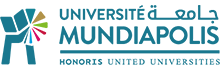

---

### Travaux Pratiques

## Les Embeddings avec LangChain et OpenAI

**Enseignant :** Pr. Habib AYAD  
**Classe :** 3ACINF DATA  
**Année universitaire :** 2026 – 2027

---

</div>

# 🧠 TP : Les Embeddings avec LangChain et OpenAI



## 🎯 Objectifs pédagogiques
À la fin de ce TP, vous serez capable de :
1. Expliquer ce qu'est un **embedding** (plongement vectoriel) et à quoi il sert.
2. Générer des embeddings avec `OpenAIEmbeddings` de **LangChain**.
3. Mesurer la **similarité** entre deux textes (similarité cosinus, distance euclidienne).
4. Construire un petit **moteur de recherche sémantique** avec un *vector store*.
5. **Visualiser** des embeddings en 2D.
6. Découper des documents longs (*chunking*) avant de les vectoriser.

## 📋 Plan du TP
| Partie | Contenu |
|---|---|
| 0 | Installation et configuration |
| 1 | Notions théoriques |
| 2 | Premier embedding |
| 3 | Mesurer la similarité |
| 4 | Recherche sémantique « à la main » |
| 5 | Vector Store LangChain |
| 6 | Visualisation 2D |
| 7 | Découpage de documents (chunking) |
| 8 | Exercices |

---
# Partie 0 — Installation et configuration

## 0.1 Installation des bibliothèques

| Bibliothèque | Rôle |
|---|---|
| `langchain-openai` | Connecteur LangChain vers les modèles OpenAI (dont les embeddings) |
| `langchain-core` | Objets de base de LangChain : `Document`, `InMemoryVectorStore`… |
| `langchain-text-splitters` | Outils pour découper des textes longs |
| `numpy` | Calcul numérique sur les vecteurs |
| `scikit-learn` | Réduction de dimension (PCA) pour la visualisation |
| `matplotlib` | Graphiques |
| `python-dotenv` | Lecture de la clé API depuis un fichier `.env` |

In [1]:
%pip install -qU langchain-ollama langchain-core langchain-text-splitters numpy scikit-learn matplotlib


Note: you may need to restart the kernel to use updated packages.


c:\Users\surfa\Desktop\IA avance cour\TP-Embedding\.venv\Scripts\python.exe: No module named pip


## 0.2 Configuration de la clé API OpenAI

Pour appeler l'API OpenAI il faut une **clé API** (à créer sur https://platform.openai.com/api-keys).

> ⚠️ **Ne jamais écrire sa clé en clair dans un notebook partagé.**
> Deux méthodes sûres :
> - un fichier `.env` contenant `OPENAI_API_KEY=sk-...` (chargé par `load_dotenv()`),
> - ou une saisie masquée avec `getpass`.

**Fonctions utilisées :**
- `load_dotenv()` : lit le fichier `.env` du dossier courant et place ses variables dans l'environnement du processus.
- `os.environ.get(nom)` : renvoie la valeur d'une variable d'environnement, ou `None` si elle n'existe pas.
- `getpass.getpass(message)` : demande une saisie à l'utilisateur **sans l'afficher** à l'écran.

In [2]:
# Pas besoin de clé API avec Ollama (exécution 100% locale)
print("Ollama configuré en local (pas de clé API requise) ✅")


Ollama configuré en local (pas de clé API requise) ✅


---
# Partie 1 — Notions théoriques

## 1.1 Qu'est-ce qu'un embedding ?

Un **embedding** est une **représentation numérique d'un texte sous forme de vecteur** (une liste de nombres réels).

```
"Le chat dort sur le canapé"  ──►  [0.012, -0.087, 0.231, ..., 0.045]   (1536 nombres)
```

L'idée clé : **des textes de sens proche donnent des vecteurs proches** dans l'espace.

| Phrase | Proximité attendue |
|---|---|
| « Le chat dort » / « Le félin se repose » | 🟢 très proches (même sens, mots différents) |
| « Le chat dort » / « La bourse a chuté » | 🔴 éloignés |

C'est ce qui permet la **recherche sémantique** : on cherche par le *sens*, pas par les mots exacts.

## 1.2 À quoi ça sert ?
- 🔎 **Recherche sémantique** (moteur de recherche intelligent)
- 🤖 **RAG** (*Retrieval-Augmented Generation*) : donner à un LLM les bons documents pour répondre
- 🗂️ **Classification** et **clustering** de textes
- 🧭 **Recommandation** de contenus similaires
- 🚨 **Détection de doublons** ou d'anomalies

## 1.3 Les modèles d'embedding d'OpenAI

| Modèle | Dimension par défaut | Remarque |
|---|---|---|
| `text-embedding-3-small` | 1536 | Rapide et peu coûteux — **utilisé dans ce TP** |
| `text-embedding-3-large` | 3072 | Plus précis, plus cher |

> 💡 Les modèles `text-embedding-3-*` permettent de **réduire la dimension** via le paramètre `dimensions` (ex. 256), au prix d'une légère perte de précision.

---
# Partie 2 — Premier embedding

## 2.1 Créer le modèle d'embedding

### 📘 `OpenAIEmbeddings(...)`
Classe LangChain qui encapsule l'API d'embeddings d'OpenAI.

| Paramètre | Description |
|---|---|
| `model` | Nom du modèle (ex. `"text-embedding-3-small"`) |
| `dimensions` | *(optionnel)* taille des vecteurs produits (uniquement modèles `-3-`) |
| `api_key` | *(optionnel)* clé API ; par défaut lue dans `OPENAI_API_KEY` |
| `chunk_size` | *(optionnel)* nombre de textes envoyés par requête (par défaut 1000) |

L'objet créé expose deux méthodes principales :
- `embed_query(texte)` → **un** vecteur (pour une question / requête)
- `embed_documents(liste_de_textes)` → **une liste** de vecteurs (pour des documents)

In [3]:
from langchain_ollama import OllamaEmbeddings

embeddings = OllamaEmbeddings(model="nomic-embed-text")
print(embeddings)


model='nomic-embed-text' dimensions=None validate_model_on_init=False base_url=None client_kwargs={} async_client_kwargs={} sync_client_kwargs={} mirostat=None mirostat_eta=None mirostat_tau=None num_ctx=None num_gpu=None keep_alive=None num_thread=None repeat_last_n=None repeat_penalty=None temperature=None stop=None tfs_z=None top_k=None top_p=None


## 2.2 Vectoriser une phrase

### 📘 `embeddings.embed_query(text: str) -> list[float]`
Envoie **un seul texte** à l'API et renvoie son embedding sous forme de liste de `float`.
On l'utilise typiquement pour la **requête** de l'utilisateur dans une recherche.

In [4]:
phrase = "Le chat dort paisiblement sur le canapé."
vecteur = embeddings.embed_query(phrase)

print("Type             :", type(vecteur))
print("Dimension        :", len(vecteur))
print("5 premières val. :", vecteur[:5])

Type             : <class 'list'>
Dimension        : 768
5 premières val. : [0.066195235, 0.021948647, -0.16556022, -0.052541424, 0.017683584]


🧐 **Observation :** le vecteur contient **1536 nombres**. Pris isolément, chacun n'a pas de signification lisible : c'est la **position globale** du vecteur dans l'espace qui encode le sens.

## 2.3 Vectoriser plusieurs documents

### 📘 `embeddings.embed_documents(texts: list[str]) -> list[list[float]]`
Vectorise **une liste de textes** en regroupant les appels à l'API (plus efficace qu'une boucle sur `embed_query`).
Renvoie une liste de vecteurs, **dans le même ordre** que les textes fournis.

In [5]:
phrases = [
    "Le chat dort paisiblement sur le canapé.",
    "Un félin se repose tranquillement sur le sofa.",
    "Le chien court dans le jardin.",
    "La bourse de Paris a fortement chuté aujourd'hui.",
    "Les marchés financiers sont en baisse.",
    "J'adore cuisiner des pâtes à la carbonara.",
]

vecteurs = embeddings.embed_documents(phrases)

print("Nombre de vecteurs :", len(vecteurs))
print("Dimension de chacun :", len(vecteurs[0]))

Nombre de vecteurs : 6
Dimension de chacun : 768


## 2.4 Réduire la dimension (optionnel)

Le paramètre `dimensions` produit des vecteurs plus courts : moins de mémoire et des calculs plus rapides.

In [6]:
v256 = vecteur[:256]
print("Dimension réduite (tronquée) :", len(v256))


Dimension réduite (tronquée) : 256


---
# Partie 3 — Mesurer la similarité entre textes

## 3.1 La similarité cosinus

Elle mesure l'**angle** entre deux vecteurs $A$ et $B$ :

$$\text{cos}(A, B) = \frac{A \cdot B}{\|A\| \times \|B\|}$$

| Valeur | Interprétation |
|---|---|
| ≈ 1 | Sens très proche |
| ≈ 0 | Sans rapport |
| < 0 | Sens opposé (rare avec les embeddings de texte) |

> 💡 Les embeddings OpenAI sont **normalisés** (norme = 1) : la similarité cosinus est alors égale au simple **produit scalaire**.

### 📘 Fonctions NumPy utilisées
- `np.array(liste)` : convertit une liste Python en tableau NumPy pour le calcul vectoriel.
- `np.dot(a, b)` : produit scalaire $\sum a_i b_i$.
- `np.linalg.norm(a)` : norme euclidienne $\sqrt{\sum a_i^2}$ (la « longueur » du vecteur).

In [8]:
import numpy as np

def similarite_cosinus(a, b):
    '''
    Calcule la similarité cosinus entre deux vecteurs.

    Paramètres
    ----------
    a, b : list[float] ou np.ndarray
        Les deux vecteurs à comparer (même dimension).

    Retour
    ------
    float : valeur entre -1 et 1 (1 = même direction = même sens).
    '''
    a, b = np.array(a), np.array(b)
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))


print("Norme d'un embedding OpenAI :", round(np.linalg.norm(vecteurs[0]), 4))
print()
print(f"chat  vs félin  : {similarite_cosinus(vecteurs[0], vecteurs[1]):.3f}")
print(f"chat  vs chien  : {similarite_cosinus(vecteurs[0], vecteurs[2]):.3f}")
print(f"chat  vs bourse : {similarite_cosinus(vecteurs[0], vecteurs[3]):.3f}")
print(f"bourse vs marchés : {similarite_cosinus(vecteurs[3], vecteurs[4]):.3f}")

Norme d'un embedding OpenAI : 1.0

chat  vs félin  : 0.563
chat  vs chien  : 0.648
chat  vs bourse : 0.608
bourse vs marchés : 0.657


🧐 **Observation :** « chat » et « félin » sont très proches **alors qu'ils ne partagent presque aucun mot**. C'est toute la puissance des embeddings.

## 3.2 La distance euclidienne

Autre mesure possible : la distance « à vol d'oiseau » entre deux points.

$$d(A, B) = \|A - B\| = \sqrt{\sum (a_i - b_i)^2}$$

Ici, **plus la distance est petite, plus les textes sont proches** (c'est l'inverse du cosinus).

In [9]:
def distance_euclidienne(a, b):
    '''
    Calcule la distance euclidienne entre deux vecteurs.

    Retour
    ------
    float : >= 0. Plus la valeur est petite, plus les textes sont proches.
    '''
    return float(np.linalg.norm(np.array(a) - np.array(b)))


print(f"chat vs félin  : {distance_euclidienne(vecteurs[0], vecteurs[1]):.3f}")
print(f"chat vs bourse : {distance_euclidienne(vecteurs[0], vecteurs[3]):.3f}")

chat vs félin  : 0.934
chat vs bourse : 0.885


## 3.3 Matrice de similarité

On calcule la similarité de **chaque phrase avec chaque autre**, puis on l'affiche sous forme de carte de chaleur (*heatmap*).

### 📘 Fonctions utilisées
- `M @ M.T` : produit matriciel ; comme les vecteurs sont normalisés, chaque case $(i, j)$ vaut la similarité cosinus entre la phrase $i$ et la phrase $j$.
- `plt.imshow(matrice, cmap=...)` : affiche une matrice comme une image colorée.
- `plt.colorbar()` : ajoute la légende des couleurs.
- `plt.xticks / plt.yticks` : place les étiquettes sur les axes.
- `plt.text(x, y, texte)` : écrit un texte à une position donnée du graphique.

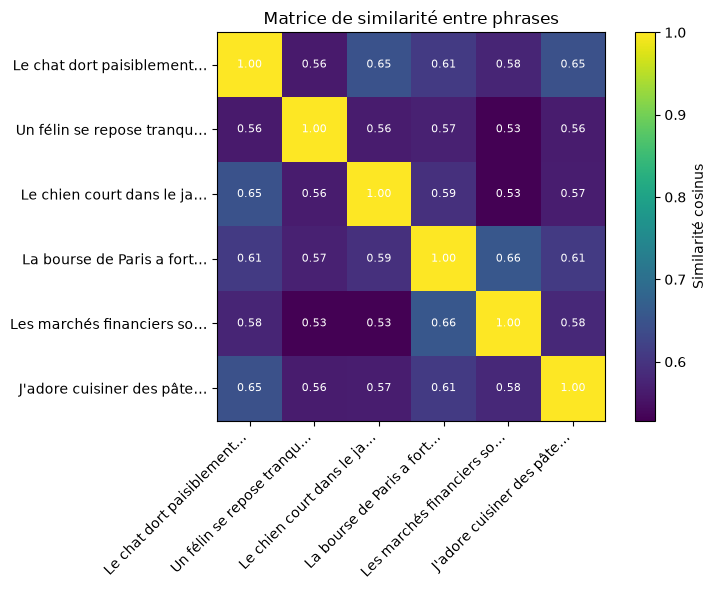

In [10]:
import matplotlib.pyplot as plt

M = np.array(vecteurs)
matrice_sim = M @ M.T

etiquettes = [p[:25] + "…" for p in phrases]

plt.figure(figsize=(8, 6))
plt.imshow(matrice_sim, cmap="viridis")
plt.colorbar(label="Similarité cosinus")
plt.xticks(range(len(phrases)), etiquettes, rotation=45, ha="right")
plt.yticks(range(len(phrases)), etiquettes)
for i in range(len(phrases)):
    for j in range(len(phrases)):
        plt.text(j, i, f"{matrice_sim[i, j]:.2f}", ha="center", va="center", color="white", fontsize=8)
plt.title("Matrice de similarité entre phrases")
plt.tight_layout()
plt.show()

---
# Partie 4 — Recherche sémantique « à la main »

Avant d'utiliser les outils de LangChain, construisons nous-mêmes un mini moteur de recherche pour comprendre le principe :

1. **Indexation** : on vectorise une fois tous les documents (`embed_documents`).
2. **Requête** : on vectorise la question (`embed_query`).
3. **Comparaison** : on calcule la similarité question ↔ chaque document.
4. **Classement** : on renvoie les *k* documents les plus similaires.

### 📘 Fonctions utilisées
- `np.argsort(tableau)` : renvoie les **indices** qui trieraient le tableau par ordre croissant.
- `[::-1]` : inverse l'ordre (pour avoir le plus similaire en premier).

In [11]:
base_connaissances = [
    "Python est un langage de programmation polyvalent et facile à apprendre.",
    "La tour Eiffel a été construite pour l'Exposition universelle de 1889.",
    "Les embeddings transforment du texte en vecteurs numériques.",
    "Le football est le sport le plus populaire au monde.",
    "LangChain est un framework pour développer des applications avec des LLM.",
    "La photosynthèse permet aux plantes de produire de l'énergie à partir de la lumière.",
    "Marrakech est une ville célèbre pour sa place Jemaa el-Fna.",
    "Les réseaux de neurones s'inspirent du fonctionnement du cerveau.",
]

# Étape 1 : indexation (une seule fois)
vecteurs_base = np.array(embeddings.embed_documents(base_connaissances))


def recherche_semantique(question, k=3):
    '''
    Renvoie les k documents de la base les plus proches de la question.

    Paramètres
    ----------
    question : str
        Texte de la requête.
    k : int
        Nombre de résultats à renvoyer.

    Retour
    ------
    list[tuple[float, str]] : couples (score, document), du plus au moins similaire.
    '''
    v_question = np.array(embeddings.embed_query(question))   # étape 2
    scores = vecteurs_base @ v_question                        # étape 3
    meilleurs = np.argsort(scores)[::-1][:k]                   # étape 4
    return [(float(scores[i]), base_connaissances[i]) for i in meilleurs]


for score, doc in recherche_semantique("Comment fonctionne l'intelligence artificielle ?"):
    print(f"{score:.3f}  |  {doc}")

0.613  |  Les réseaux de neurones s'inspirent du fonctionnement du cerveau.
0.589  |  Python est un langage de programmation polyvalent et facile à apprendre.
0.578  |  Le football est le sport le plus populaire au monde.


In [12]:
# Essayez d'autres questions !
for q in ["monument parisien", "outil pour créer un chatbot", "voyage au Maroc"]:
    print(f"\n🔎 {q}")
    for score, doc in recherche_semantique(q, k=2):
        print(f"   {score:.3f}  |  {doc}")


🔎 monument parisien
   0.617  |  La tour Eiffel a été construite pour l'Exposition universelle de 1889.
   0.577  |  Le football est le sport le plus populaire au monde.

🔎 outil pour créer un chatbot
   0.586  |  Python est un langage de programmation polyvalent et facile à apprendre.
   0.578  |  LangChain est un framework pour développer des applications avec des LLM.

🔎 voyage au Maroc
   0.617  |  Marrakech est une ville célèbre pour sa place Jemaa el-Fna.
   0.519  |  Le football est le sport le plus populaire au monde.


🧐 **Observation :** la requête « monument parisien » trouve la tour Eiffel **sans** que les mots « monument » ou « parisien » apparaissent dans le document.

---
# Partie 5 — Le Vector Store de LangChain

Un **vector store** (base vectorielle) automatise ce que nous venons de faire : il **stocke** les documents avec leurs embeddings et **recherche** les plus proches.
En production on utilise FAISS, Chroma, Pinecone, pgvector… Ici on prend `InMemoryVectorStore` (en mémoire, sans installation).

## 5.1 L'objet `Document`

### 📘 `Document(page_content: str, metadata: dict = {})`
Unité de base de LangChain pour représenter un texte.
- `page_content` : le texte lui-même.
- `metadata` : un dictionnaire d'informations complémentaires (source, auteur, catégorie, date…), très utile pour **filtrer** ou **citer** les sources.

In [13]:
from langchain_core.documents import Document

documents = [
    Document(page_content="Python est un langage de programmation polyvalent.", metadata={"categorie": "informatique"}),
    Document(page_content="LangChain facilite la création d'applications avec des LLM.", metadata={"categorie": "informatique"}),
    Document(page_content="Les embeddings représentent le sens d'un texte par un vecteur.", metadata={"categorie": "informatique"}),
    Document(page_content="La tour Eiffel mesure environ 330 mètres.", metadata={"categorie": "tourisme"}),
    Document(page_content="Chefchaouen est surnommée la perle bleue du Maroc.", metadata={"categorie": "tourisme"}),
    Document(page_content="Le Real Madrid a remporté de nombreuses Ligues des champions.", metadata={"categorie": "sport"}),
    Document(page_content="Le marathon est une course de 42,195 km.", metadata={"categorie": "sport"}),
]

print(documents[0])
print("Texte     :", documents[0].page_content)
print("Métadonnées :", documents[0].metadata)

page_content='Python est un langage de programmation polyvalent.' metadata={'categorie': 'informatique'}
Texte     : Python est un langage de programmation polyvalent.
Métadonnées : {'categorie': 'informatique'}


## 5.2 Créer le vector store

### 📘 `InMemoryVectorStore.from_documents(documents, embedding)`
Méthode de classe qui :
1. calcule l'embedding de chaque document avec le modèle `embedding`,
2. stocke textes + vecteurs + métadonnées en mémoire,
3. renvoie le vector store prêt à être interrogé.

> Il existe aussi `from_texts(textes, embedding, metadatas=...)` pour partir de simples chaînes.

In [14]:
from langchain_core.vectorstores import InMemoryVectorStore

vector_store = InMemoryVectorStore.from_documents(documents, embedding=embeddings)
print("Vector store créé ✅")

Vector store créé ✅


## 5.3 Rechercher des documents

### 📘 `vector_store.similarity_search(query, k=4)`
Vectorise `query`, puis renvoie la liste des `k` **`Document`** les plus proches.

### 📘 `vector_store.similarity_search_with_score(query, k=4)`
Identique, mais renvoie des couples `(Document, score)` : pratique pour voir **à quel point** chaque résultat est pertinent.

In [15]:
resultats = vector_store.similarity_search("Quel framework utiliser pour les LLM ?", k=2)
for doc in resultats:
    print(f"- {doc.page_content}  [{doc.metadata['categorie']}]")

- LangChain facilite la création d'applications avec des LLM.  [informatique]
- Le Real Madrid a remporté de nombreuses Ligues des champions.  [sport]


In [16]:
resultats = vector_store.similarity_search_with_score("une belle ville à visiter", k=3)
for doc, score in resultats:
    print(f"{score:.3f}  |  {doc.page_content}")

0.568  |  Chefchaouen est surnommée la perle bleue du Maroc.
0.564  |  La tour Eiffel mesure environ 330 mètres.
0.502  |  Les embeddings représentent le sens d'un texte par un vecteur.


## 5.4 Filtrer par métadonnées

Avec `InMemoryVectorStore`, le paramètre `filter` accepte une **fonction** qui reçoit un `Document` et renvoie `True` s'il doit être conservé.
(Les autres vector stores utilisent souvent un dictionnaire, ex. `filter={"categorie": "sport"}`.)

In [17]:
def seulement_sport(doc: Document) -> bool:
    '''Garde uniquement les documents de la catégorie "sport".'''
    return doc.metadata.get("categorie") == "sport"

resultats = vector_store.similarity_search("compétition", k=3, filter=seulement_sport)
for doc in resultats:
    print("-", doc.page_content)

- Le Real Madrid a remporté de nombreuses Ligues des champions.
- Le marathon est une course de 42,195 km.


## 5.5 Ajouter des documents

### 📘 `vector_store.add_documents(documents)`
Vectorise et ajoute de nouveaux documents à un vector store existant. Renvoie la liste de leurs identifiants.

In [18]:
ids = vector_store.add_documents([
    Document(page_content="Le couscous est un plat traditionnel du Maghreb.", metadata={"categorie": "cuisine"}),
])
print("Identifiants ajoutés :", ids)

for doc in vector_store.similarity_search("spécialité culinaire marocaine", k=1):
    print("-", doc.page_content)

Identifiants ajoutés : ['d7424900-5fb9-4924-9303-e341f981f908']
- Chefchaouen est surnommée la perle bleue du Maroc.


## 5.6 Transformer le vector store en *retriever*

### 📘 `vector_store.as_retriever(search_type="similarity", search_kwargs={"k": 2})`
Crée un **retriever** : un objet standard de LangChain qui prend une question et renvoie des documents.
C'est la brique utilisée dans les chaînes **RAG**.

| `search_type` | Comportement |
|---|---|
| `"similarity"` | Les k plus proches (par défaut) |
| `"mmr"` | *Maximal Marginal Relevance* : pertinents **et** variés (évite les doublons) |
| `"similarity_score_threshold"` | Seulement ceux au-dessus d'un score minimum |

### 📘 `retriever.invoke(question)`
Méthode standard (interface *Runnable*) qui exécute la recherche et renvoie une liste de `Document`.

In [19]:
retriever = vector_store.as_retriever(search_type="similarity", search_kwargs={"k": 2})

for doc in retriever.invoke("apprendre à coder"):
    print("-", doc.page_content)

- Python est un langage de programmation polyvalent.
- LangChain facilite la création d'applications avec des LLM.


---
# Partie 6 — Visualiser les embeddings en 2D

Impossible de dessiner un espace à 1536 dimensions ! On utilise une **réduction de dimension** pour projeter les vecteurs en 2D tout en conservant au mieux leurs distances.

### 📘 `PCA(n_components=2)` (scikit-learn)
**Analyse en Composantes Principales** : trouve les 2 directions qui expliquent le plus de variance dans les données.
- `pca.fit_transform(X)` : apprend ces directions sur `X` **et** projette les données → tableau de forme `(n, 2)`.
- `pca.explained_variance_ratio_` : part de l'information conservée par chaque axe.

### 📘 `plt.scatter(x, y, c=..., label=...)`
Dessine un nuage de points.

Variance expliquée par les 2 axes : 0.213


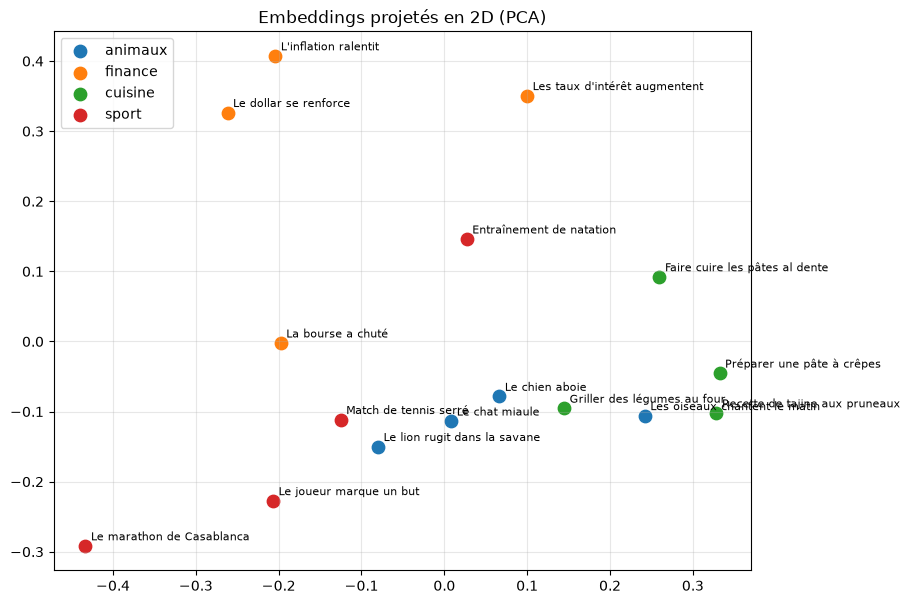

In [22]:
from sklearn.decomposition import PCA

corpus = {
    "animaux":  ["Le chat miaule", "Le chien aboie", "Le lion rugit dans la savane", "Les oiseaux chantent le matin"],
    "finance":  ["La bourse a chuté", "Les taux d'intérêt augmentent", "L'inflation ralentit", "Le dollar se renforce"],
    "cuisine":  ["Recette de tajine aux pruneaux", "Faire cuire les pâtes al dente", "Préparer une pâte à crêpes", "Griller des légumes au four"],
    "sport":    ["Le joueur marque un but", "Le marathon de Casablanca", "Match de tennis serré", "Entraînement de natation"],
}

textes, categories = [], []
for cat, liste in corpus.items():
    textes += liste
    categories += [cat] * len(liste)

X = np.array(embeddings.embed_documents(textes))

pca = PCA(n_components=2)
X_2d = pca.fit_transform(X)
print("Variance expliquée par les 2 axes :", pca.explained_variance_ratio_.sum().round(3))

plt.figure(figsize=(9, 7))
for cat in corpus:
    idx = [i for i, c in enumerate(categories) if c == cat]
    plt.scatter(X_2d[idx, 0], X_2d[idx, 1], label=cat, s=80)
    for i in idx:
        plt.annotate(textes[i], (X_2d[i, 0], X_2d[i, 1]), fontsize=8, xytext=(4, 4), textcoords="offset points")
plt.legend()
plt.title("Embeddings projetés en 2D (PCA)")
plt.grid(alpha=0.3)
plt.show()

🧐 **Observation :** les phrases d'une même thématique forment des **groupes (clusters)**, sans qu'on ait jamais indiqué les catégories au modèle.

> 💡 Pour aller plus loin, essayez `sklearn.manifold.TSNE` ou la bibliothèque `umap-learn`, qui conservent mieux les voisinages locaux.

---
# Partie 7 — Découper des documents longs (chunking)

Un modèle d'embedding a une **limite de taille d'entrée** (≈ 8 191 *tokens* pour OpenAI) et, surtout, un vecteur unique pour un très long texte « dilue » le sens.
On découpe donc les documents en **morceaux (chunks)** avant de les vectoriser.

### 📘 `RecursiveCharacterTextSplitter(chunk_size, chunk_overlap)`
Découpe un texte en essayant de couper d'abord aux paragraphes (`\n\n`), puis aux lignes (`\n`), puis aux espaces, pour garder des morceaux cohérents.

| Paramètre | Description |
|---|---|
| `chunk_size` | Taille maximale d'un morceau (en caractères) |
| `chunk_overlap` | Nombre de caractères **communs** entre deux morceaux consécutifs (évite de couper une idée en deux) |

### 📘 `splitter.split_text(texte)` → `list[str]`
### 📘 `splitter.create_documents([texte], metadatas=[...])` → `list[Document]`

In [24]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

texte_long = '''
Les embeddings sont au cœur des applications modernes de traitement du langage.
Ils permettent de représenter des mots, des phrases ou des documents entiers sous forme de vecteurs.

Le RAG, ou Retrieval-Augmented Generation, combine une recherche dans une base vectorielle
avec un modèle de langage. On récupère d'abord les passages pertinents, puis on les donne au LLM.

Le choix de la taille des morceaux est important. Des morceaux trop petits perdent le contexte,
des morceaux trop grands mélangent plusieurs idées et rendent la recherche moins précise.

Enfin, les métadonnées comme la source ou la page permettent de citer l'origine de chaque réponse.
'''

splitter = RecursiveCharacterTextSplitter(chunk_size=200, chunk_overlap=30)
chunks = splitter.create_documents([texte_long], metadatas=[{"source": "cours_embeddings"}])

print(f"{len(chunks)} morceaux créés\n")
for i, c in enumerate(chunks):
    print(f"--- Chunk {i} ({len(c.page_content)} caractères) ---")
    print(c.page_content, "\n")

4 morceaux créés

--- Chunk 0 (180 caractères) ---
Les embeddings sont au cœur des applications modernes de traitement du langage.
Ils permettent de représenter des mots, des phrases ou des documents entiers sous forme de vecteurs. 

--- Chunk 1 (188 caractères) ---
Le RAG, ou Retrieval-Augmented Generation, combine une recherche dans une base vectorielle
avec un modèle de langage. On récupère d'abord les passages pertinents, puis on les donne au LLM. 

--- Chunk 2 (185 caractères) ---
Le choix de la taille des morceaux est important. Des morceaux trop petits perdent le contexte,
des morceaux trop grands mélangent plusieurs idées et rendent la recherche moins précise. 

--- Chunk 3 (98 caractères) ---
Enfin, les métadonnées comme la source ou la page permettent de citer l'origine de chaque réponse. 



In [25]:
# On indexe les morceaux et on interroge
store_chunks = InMemoryVectorStore.from_documents(chunks, embedding=embeddings)

for doc, score in store_chunks.similarity_search_with_score("Comment choisir la taille des chunks ?", k=2):
    print(f"{score:.3f}  |  {doc.page_content[:100]}…  (source : {doc.metadata['source']})")

0.659  |  Le choix de la taille des morceaux est important. Des morceaux trop petits perdent le contexte,
des …  (source : cours_embeddings)
0.629  |  Enfin, les métadonnées comme la source ou la page permettent de citer l'origine de chaque réponse.…  (source : cours_embeddings)


---
# Partie 8 — Exercices ✍️

### Exercice 1 — Synonymes et paraphrases
Écrivez 3 paires de phrases qui ont **le même sens avec des mots différents**, et 3 paires qui partagent **les mêmes mots mais un sens différent** (ex. « Il a pris l'avocat » : fruit / juriste).
Calculez la similarité cosinus de chaque paire. Que constatez-vous ?

In [26]:
# 1. Paires avec le même sens (mots différents / paraphrases)
paires_synonymes = [
    ("Le médecin examine son patient.", "Le docteur ausculte le malade."),
    ("Cette voiture est très rapide.", "Cette automobile a une grande vitesse."),
    ("Il a acheté un nouvel ordinateur.", "Il s'est procuré un nouveau PC."),
]

# 2. Paires avec les mêmes mots mais un sens différent (polysémie / homonymes)
paires_polysemie = [
    ("Il a mangé un avocat bien mûr.", "Il a engagé un avocat pour son procès."),
    ("J'ai déposé mon argent à la banque.", "Il s'est assis sur la berge près de la banque du fleuve."),
    ("La pièce de théâtre était formidable.", "Il a trouvé une pièce de monnaie au sol."),
]

print("===  Paires de même sens (mots différents) ===")
for p1, p2 in paires_synonymes:
    v1, v2 = embeddings.embed_query(p1), embeddings.embed_query(p2)
    sim = similarite_cosinus(v1, v2)
    print(f"Similarité : {sim:.3f}")
    print(f"  A : {p1}\n  B : {p2}\n")

print("===  Paires avec des mots identiques (sens différent) ===")
for p1, p2 in paires_polysemie:
    v1, v2 = embeddings.embed_query(p1), embeddings.embed_query(p2)
    sim = similarite_cosinus(v1, v2)
    print(f"Similarité : {sim:.3f}")
    print(f"  A : {p1}\n  B : {p2}\n")


===  Paires de même sens (mots différents) ===
Similarité : 0.668
  A : Le médecin examine son patient.
  B : Le docteur ausculte le malade.

Similarité : 0.694
  A : Cette voiture est très rapide.
  B : Cette automobile a une grande vitesse.

Similarité : 0.576
  A : Il a acheté un nouvel ordinateur.
  B : Il s'est procuré un nouveau PC.

===  Paires avec des mots identiques (sens différent) ===
Similarité : 0.771
  A : Il a mangé un avocat bien mûr.
  B : Il a engagé un avocat pour son procès.

Similarité : 0.722
  A : J'ai déposé mon argent à la banque.
  B : Il s'est assis sur la berge près de la banque du fleuve.

Similarité : 0.594
  A : La pièce de théâtre était formidable.
  B : Il a trouvé une pièce de monnaie au sol.



### Exercice 2 — Multilingue
Les embeddings OpenAI sont **multilingues**. Comparez la similarité entre :
- « J'aime le café » (français)
- « I love coffee » (anglais)
- « أحب القهوة » (arabe)
- « J'aime le football » (français)

La langue compte-t-elle plus que le sens ?

In [30]:
phrases_multi = {
    "FR (café)"    : "J'aime le café",
    "EN (café)"    : "I love coffee",
    "AR (café)"    : "أحب القهوة",
    "FR (football)": "J'aime le football",
}

# Calcul de tous les embeddings
vecteurs_multi = {lang: embeddings.embed_query(txt) for lang, txt in phrases_multi.items()}

ref = vecteurs_multi["FR (café)"]

print("Comparaison par rapport à « J'aime le café » (FR) :")
for nom, v in vecteurs_multi.items():
    if nom != "FR (café)":
        sim = similarite_cosinus(ref, v)
        print(f"  vs {nom:<15} : {sim:.3f}")


Comparaison par rapport à « J'aime le café » (FR) :
  vs EN (café)       : 0.584
  vs AR (café)       : 0.422
  vs FR (football)   : 0.697


### Exercice 3 — Impact de la dimension
Créez trois modèles avec `dimensions=64`, `256` et `1536`. Pour la base de la partie 4, comparez le classement des résultats pour une même question. À partir de quelle dimension les résultats changent-ils ?

In [28]:
dimensions_a_tester = [64, 256, len(vecteurs_base[0])]  # ex: 768 avec Ollama ou 1536 avec OpenAI
question_test = "Comment fonctionne l'intelligence artificielle ?"

print(f"Question test : '{question_test}'\n")

for d in dimensions_a_tester:
    # Réduction par troncature et re-normalisation
    v_base_red = vecteurs_base[:, :d]
    v_base_red = v_base_red / np.linalg.norm(v_base_red, axis=1, keepdims=True)
    
    v_q = np.array(embeddings.embed_query(question_test))[:d]
    v_q = v_q / np.linalg.norm(v_q)
    
    scores = v_base_red @ v_q
    top_indices = np.argsort(scores)[::-1][:3]
    
    print(f"--- Top 3 avec dimension = {d} ---")
    for idx in top_indices:
        print(f"  {scores[idx]:.3f} | {base_connaissances[idx]}")
    print()


Question test : 'Comment fonctionne l'intelligence artificielle ?'

--- Top 3 avec dimension = 64 ---
  0.667 | Les embeddings transforment du texte en vecteurs numériques.
  0.656 | Python est un langage de programmation polyvalent et facile à apprendre.
  0.627 | Les réseaux de neurones s'inspirent du fonctionnement du cerveau.

--- Top 3 avec dimension = 256 ---
  0.620 | Les réseaux de neurones s'inspirent du fonctionnement du cerveau.
  0.611 | Python est un langage de programmation polyvalent et facile à apprendre.
  0.610 | Le football est le sport le plus populaire au monde.

--- Top 3 avec dimension = 768 ---
  0.613 | Les réseaux de neurones s'inspirent du fonctionnement du cerveau.
  0.589 | Python est un langage de programmation polyvalent et facile à apprendre.
  0.578 | Le football est le sport le plus populaire au monde.



### Exercice 4 — Mini FAQ intelligente
1. Créez une liste de 8 à 10 couples *question / réponse* (par exemple sur votre établissement).
2. Indexez **les questions** dans un `InMemoryVectorStore`, en plaçant la réponse dans les `metadata`.
3. Écrivez une fonction `repondre(question_utilisateur)` qui trouve la question la plus proche et renvoie sa réponse.
4. Bonus : si le meilleur score est inférieur à un seuil (ex. 0,4), renvoyez « Je ne sais pas ».

In [29]:
faq_data = [
    ("Quels sont les horaires d'ouverture ?", "L'établissement est ouvert du lundi au vendredi de 8h à 18h."),
    ("Où se trouve le campus universitaire ?", "Le campus est situé à Casablanca, sur la route de Nouaceur."),
    ("Comment s'inscrire en master ?", "Les inscriptions se font en ligne sur le portail des admissions avant le 15 juillet."),
    ("Y a-t-il une bibliothèque sur place ?", "Oui, la bibliothèque est accessible aux étudiants au bâtiment B."),
    ("Comment contacter le secrétariat ?", "Vous pouvez écrire à contact@mundiapolis.ma ou appeler le 0522000000."),
    ("Quelles sont les filières d'ingénierie ?", "Nous proposons Génie Informatique, Data Science, et Génie Industriel."),
    ("Y a-t-il un restaurant ou une cafétéria ?", "Oui, deux cafétérias sont disponibles sur le campus principal."),
    ("Existe-t-il des bourses d'études ?", "Des bourses au mérite sont attribuées selon le dossier académique."),
]

# 1 & 2. Création des documents (page_content = question, metadata = réponse)
faq_docs = [
    Document(page_content=q, metadata={"reponse": r})
    for q, r in faq_data
]

faq_store = InMemoryVectorStore.from_documents(faq_docs, embedding=embeddings)

# 3 & 4. Fonction de réponse avec seuil de confiance
def repondre(question_utilisateur: str, seuil: float = 0.5) -> str:
    resultats = faq_store.similarity_search_with_score(question_utilisateur, k=1)
    if not resultats:
        return "Je ne sais pas."
    
    doc, score = resultats[0]
    # score cosinus (proche de 1 = très confiant)
    if score < seuil:
        return f"Je ne sais pas. (Score trop faible : {score:.2f})"
    
    return f"[{score:.2f}] {doc.metadata['reponse']}"

# Tests
tests = [
    "A quelle heure ferme l'école ?",
    "Puis-je manger sur le campus ?",
    "Comment postuler pour un master en informatique ?",
    "Quelle est la recette de la tarte aux pommes ?",  # Hors sujet -> doit déclencher le seuil
]

for t in tests:
    print(f"❓ {t}")
    print(f"💡 {repondre(t)}\n")


❓ A quelle heure ferme l'école ?
💡 [0.66] Oui, deux cafétérias sont disponibles sur le campus principal.

❓ Puis-je manger sur le campus ?
💡 [0.83] Le campus est situé à Casablanca, sur la route de Nouaceur.

❓ Comment postuler pour un master en informatique ?
💡 [0.83] Les inscriptions se font en ligne sur le portail des admissions avant le 15 juillet.

❓ Quelle est la recette de la tarte aux pommes ?
💡 [0.65] Oui, deux cafétérias sont disponibles sur le campus principal.



### Exercice 5 — Classification sans entraînement (*zero-shot*)
Définissez des étiquettes (`"sport"`, `"politique"`, `"technologie"`, `"cuisine"`) et vectorisez-les.
Pour chaque nouvelle phrase, attribuez l'étiquette dont l'embedding est le plus proche. Testez sur 10 phrases et calculez le taux de réussite.

In [31]:
categories = ["sport", "politique", "technologie", "cuisine"]

# 1. Vectorisation des étiquettes
vecteurs_categories = {cat: np.array(embeddings.embed_query(cat)) for cat in categories}

# Normalisation
for cat in vecteurs_categories:
    vecteurs_categories[cat] /= np.linalg.norm(vecteurs_categories[cat])

# 2. Jeu de test : 10 phrases avec leur catégorie réelle
jeu_test = [
    ("Le gouvernement a voté le budget de l'année.", "politique"),
    ("L'attaquant a marqué un triplé en finale.", "sport"),
    ("Cette nouvelle carte graphique offre des performances incroyables.", "technologie"),
    ("Laissez mijoter la sauce à feu doux pendant vingt minutes.", "cuisine"),
    ("Les élections législatives se tiendront dimanche.", "politique"),
    ("Le smartphone pliable intègre un processeur gravé en 3nm.", "technologie"),
    ("Elle s'entraîne tous les matins pour courir le semi-marathon.", "sport"),
    ("Ajoutez une pincée de sel et du poivre noir moulu.", "cuisine"),
    ("Le président a rencontré les ministres lors du sommet.", "politique"),
    ("Le nouveau modèle d'intelligence artificielle surpasse les humains au codage.", "technologie"),
]

def classifier_zero_shot(phrase: str) -> str:
    v_phrase = np.array(embeddings.embed_query(phrase))
    v_phrase /= np.linalg.norm(v_phrase)
    
    scores = {cat: float(np.dot(v_phrase, v_cat)) for cat, v_cat in vecteurs_categories.items()}
    return max(scores, key=scores.get)

# 3. Évaluation
correct = 0
print(f"{'Phrase':<60} | {'Prédit':<12} | {'Réel':<12} | Statut")
print("-" * 95)

for phrase, vrai_label in jeu_test:
    pred = classifier_zero_shot(phrase)
    est_correct = (pred == vrai_label)
    if est_correct:
        correct += 1
    statut = "✅" if est_correct else "❌"
    print(f"{phrase[:58]:<60} | {pred:<12} | {vrai_label:<12} | {statut}")

precision = (correct / len(jeu_test)) * 100
print("-" * 95)
print(f"Taux de réussite (Accuracy) : {precision:.1f}% ({correct}/{len(jeu_test)})")


Phrase                                                       | Prédit       | Réel         | Statut
-----------------------------------------------------------------------------------------------
Le gouvernement a voté le budget de l'année.                 | politique    | politique    | ✅
L'attaquant a marqué un triplé en finale.                    | politique    | sport        | ❌
Cette nouvelle carte graphique offre des performances incr   | politique    | technologie  | ❌
Laissez mijoter la sauce à feu doux pendant vingt minutes.   | cuisine      | cuisine      | ✅
Les élections législatives se tiendront dimanche.            | politique    | politique    | ✅
Le smartphone pliable intègre un processeur gravé en 3nm.    | politique    | technologie  | ❌
Elle s'entraîne tous les matins pour courir le semi-marath   | politique    | sport        | ❌
Ajoutez une pincée de sel et du poivre noir moulu.           | politique    | cuisine      | ❌
Le président a rencontré les ministres lors 

---
# 📝 Récapitulatif

| Fonction / Classe | Rôle |
|---|---|
| `OpenAIEmbeddings(model=...)` | Crée le modèle d'embedding OpenAI |
| `embed_query(texte)` | Vectorise **un** texte (requête) |
| `embed_documents(textes)` | Vectorise **plusieurs** textes (documents) |
| `Document(page_content, metadata)` | Représente un texte et ses informations |
| `InMemoryVectorStore.from_documents(...)` | Crée une base vectorielle en mémoire |
| `similarity_search(query, k)` | Renvoie les k documents les plus proches |
| `similarity_search_with_score(query, k)` | Idem, avec les scores |
| `add_documents(docs)` | Ajoute des documents à la base |
| `as_retriever(...)` / `invoke(q)` | Interface standard de recherche (RAG) |
| `RecursiveCharacterTextSplitter` | Découpe les textes longs en morceaux |
| `PCA(n_components=2)` | Projette les vecteurs en 2D pour les visualiser |

## 🔑 À retenir
1. Un embedding transforme un texte en **vecteur** qui encode son **sens**.
2. Des textes de sens proche ⇒ des vecteurs proches (**similarité cosinus** élevée).
3. La recherche sémantique = vectoriser la requête + trouver les vecteurs les plus proches.
4. On **découpe** les longs documents et on ajoute des **métadonnées** avant d'indexer.
5. Ces briques constituent la base de tout système **RAG**.

## ➡️ Pour aller plus loin
- Remplacer `InMemoryVectorStore` par **FAISS** ou **Chroma** pour persister la base sur disque.
- Brancher le retriever sur un LLM (`ChatOpenAI`) pour construire un **chatbot RAG** complet.
- Documentation : https://python.langchain.com/docs/integrations/text_embedding/openai/